In [1]:
from google.colab import files

# Выведет кнопку «Выбрать файлы» прямо в блокноте
uploaded = files.upload()

Saving Gorillaz - Feel Good (Simple Guitar Tab).mp4 to Gorillaz - Feel Good (Simple Guitar Tab).mp4
Saving hand_landmarker.task to hand_landmarker.task


In [2]:
!pip install mediapipe opencv-python numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.5/41.5 MB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 10.6 MB/s eta 0:00:00
  Attempting uninstall: absl-py
    Found existing installation: absl-py 1.4.0
    Uninstalling absl-py-1.4.0:
      Successfully uninstalled absl-py-1.4.0


In [3]:
import cv2
import mediapipe as mp
import numpy as np
import matplotlib.pyplot as plt

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

print("OpenCV version:", cv2.__version__)
print("MediaPipe version:", mp.__version__)

OpenCV version: 5.0.0
MediaPipe version: 1.1.1


In [4]:
model_path = 'hand_landmarker.task'

base_options = python.BaseOptions(model_asset_path=model_path)
options = vision.HandLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.VIDEO, # Обрабатываем отдельные кадры/изображения
    num_hands=2,                          # Ищем до двух рук (левая и правая)
    min_hand_detection_confidence=0.5,
    min_hand_presence_confidence=0.5,
    min_tracking_confidence=0.5
)

# Создаем детектор рук
detector = vision.HandLandmarker.create_from_options(options)
print("Детектор успешно инициализирован!")

Детектор успешно инициализирован!


In [5]:
# Канонические соединения пальцев в MediaPipe Hands
HAND_CONNECTIONS = mp.tasks.vision.HandLandmarksConnections.HAND_CONNECTIONS

def draw_landmarks_on_image(rgb_image, detection_result):
    """Рисует скелет рук поверх изображения с помощью OpenCV."""
    annotated_image = rgb_image.copy()
    h, w, _ = annotated_image.shape

    if not detection_result.hand_landmarks:
        return annotated_image

    for idx, hand_landmarks in enumerate(detection_result.hand_landmarks):
        # Получаем метку руки (Left/Right) если доступна
        if detection_result.handedness and idx < len(detection_result.handedness):
            handedness_label = detection_result.handedness[idx][0].category_name
        else:
            handedness_label = "Unknown"

        # Переводим нормализованные координаты (0.0 - 1.0) в пиксели
        landmark_px = []
        for lm in hand_landmarks:
            cx, cy = int(lm.x * w), int(lm.y * h)
            landmark_px.append((cx, cy))
            # Рисуем саму точку сустава
            cv2.circle(annotated_image, (cx, cy), 4, (0, 255, 0), -1)

        # Рисуем линии скелета
        for connection in HAND_CONNECTIONS:
            pt1 = landmark_px[connection.start]
            pt2 = landmark_px[connection.end]
            cv2.line(annotated_image, pt1, pt2, (255, 0, 0), 2)

        # Подписываем руку у запястья (точка 0)
        if landmark_px:
            cv2.putText(
                annotated_image,
                handedness_label,
                (landmark_px[0][0] - 10, landmark_px[0][1] - 10),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 255, 255),
                2
            )

    return annotated_image

In [6]:
def process_guitar_video_new(input_path, output_path, max_frames=None):
    cap = cv2.VideoCapture(input_path)

    if not cap.isOpened():
        print(f"Ошибка: не удалось открыть файл {input_path}")
        return

    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    print(f"Видео: {width}x{height}, {fps} FPS, всего кадров: {total_frames}")

    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

    frame_count = 0
    frames_with_detection = 0
    total_hands = 0
    t0 = time.time()

    try:
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break

            frame_count += 1
            if max_frames and frame_count > max_frames:
                break

            # OpenCV читает в BGR, MediaPipe Tasks требует RGB объект mp.Image
            image_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=image_rgb)

            timestamp_ms = int(cap.get(cv2.CAP_PROP_POS_MSEC))
            detection_result = detector.detect_for_video(mp_image, timestamp_ms)

            # Статистика
            if detection_result.hand_landmarks:
                frames_with_detection += 1
                total_hands += len(detection_result.hand_landmarks)

            # Рисуем сразу в BGR (исходный кадр)
            annotated_bgr = draw_landmarks_on_image(frame, detection_result)
            out.write(annotated_bgr)

            if frame_count % int(fps) == 0:
                print(f"Обработано кадров: {frame_count}/{total_frames}")

    finally:
        cap.release()
        out.release()
        elapsed = time.time() - t0
        proc_fps = frame_count / elapsed if elapsed > 0 else 0
        det_pct = (frames_with_detection / frame_count * 100) if frame_count else 0
        avg_hands = (total_hands / frame_count) if frame_count else 0

        print(f"Готово! Результат сохранен в {output_path}")
        print(f"FPS обработки: {proc_fps:.2f}")
        print(f"Кадров с детекцией: {frames_with_detection}/{frame_count} ({det_pct:.1f}%)")
        print(f"Среднее число рук на кадр: {avg_hands:.2f}")


In [8]:
import time
# Замени 'test_guitar.mp4' на путь к своему видеофайлу
videos = [
    'Gorillaz - Feel Good (Simple Guitar Tab).mp4',
    # 'video2.mp4',
    # 'video3.mp4',
]
for v in videos:
    process_guitar_video_new(v, f'output_hands_{v}', max_frames=None)

Видео: 1280x720, 25.0 FPS, всего кадров: 1517
Обработано кадров: 25/1517
Обработано кадров: 50/1517
Обработано кадров: 75/1517
Обработано кадров: 100/1517
Обработано кадров: 125/1517
Обработано кадров: 150/1517
Обработано кадров: 175/1517
Обработано кадров: 200/1517
Обработано кадров: 225/1517
Обработано кадров: 250/1517
Обработано кадров: 275/1517
Обработано кадров: 300/1517
Обработано кадров: 325/1517
Обработано кадров: 350/1517
Обработано кадров: 375/1517
Обработано кадров: 400/1517
Обработано кадров: 425/1517
Обработано кадров: 450/1517
Обработано кадров: 475/1517
Обработано кадров: 500/1517
Обработано кадров: 525/1517
Обработано кадров: 550/1517
Обработано кадров: 575/1517
Обработано кадров: 600/1517
Обработано кадров: 625/1517
Обработано кадров: 650/1517
Обработано кадров: 675/1517
Обработано кадров: 700/1517
Обработано кадров: 725/1517
Обработано кадров: 750/1517
Обработано кадров: 775/1517
Обработано кадров: 800/1517
Обработано кадров: 825/1517
Обработано кадров: 850/1517
Обраб

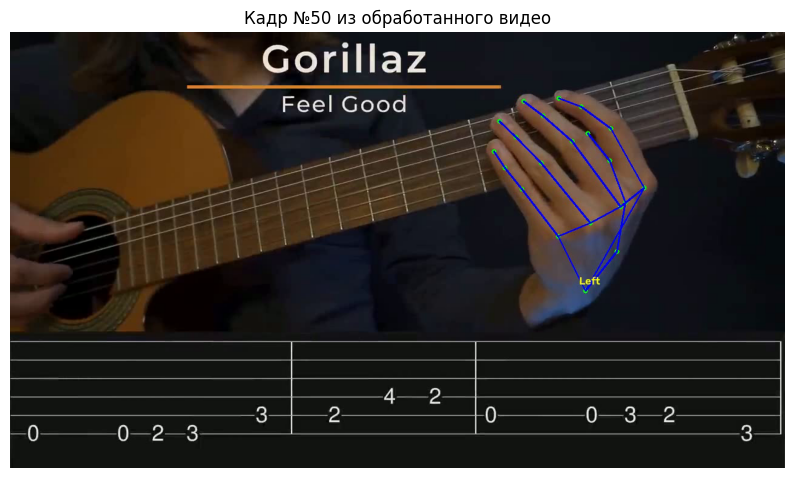

ok!


In [9]:
def show_sample_frame(video_path, frame_number=50):
    cap = cv2.VideoCapture(video_path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    ret, frame = cap.read()
    cap.release()

    if ret:
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(10, 6))
        plt.imshow(frame_rgb)
        plt.axis('off')
        plt.title(f"Кадр №{frame_number} из обработанного видео")
        plt.show()

show_sample_frame(f'output_hands_{videos[0]}', frame_number=50)
print("ok!")

In [ ]:
import os

# Посмотреть текущую папку и все файлы в ней
print("Текущая папка:", os.getcwd())

Текущая папка: /content
